# Laborator 8, Exercițiul 1
## Distribuția a posteriori a numărului de clienți $n$

### Notații

- $\theta$: probabilitatea (cunoscută) ca un client să cumpere;
- $Y$: numărul observat de cumpărători;
- $n$: numărul total de clienți (necunoscut, parametrul de interes).

PyMC: `chains=4`, `draws=2000` per lanț (`tune=2000`), `random_seed=42`.

## 1) Posteriorul lui $n$ pentru toate combinațiile $(Y, \theta)$

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pymc as pm
import arviz as az
from arviz_plots import PlotCollection

Y_values = [0, 5, 10]
theta_values = [0.2, 0.5]


def posterior_n(Y, theta):
    with pm.Model() as model:
        n = pm.Poisson("n", 10)                       # prior
        pm.Binomial("Y", n=n, p=theta, observed=Y)    # verosimilitate, theta cunoscut
        idata = pm.sample(2000, tune=2000, chains=4, random_seed=42)
    return idata.posterior["n"].values                # (chain, draw)


# strangem posteriorul lui n pentru fiecare combinatie, cu o eticheta descriptiva
posteriori = {}
for Y in Y_values:
    for theta in theta_values:
        posteriori[f"Y={Y}, theta={theta}"] = posterior_n(Y, theta)

Multiprocess sampling (4 chains in 4 jobs)
Metropolis: [n]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.
Multiprocess sampling (4 chains in 4 jobs)
Metropolis: [n]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.
Multiprocess sampling (4 chains in 4 jobs)
Metropolis: [n]


Output()

... (3 outputs left out)

Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.
Multiprocess sampling (4 chains in 4 jobs)
Metropolis: [n]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.


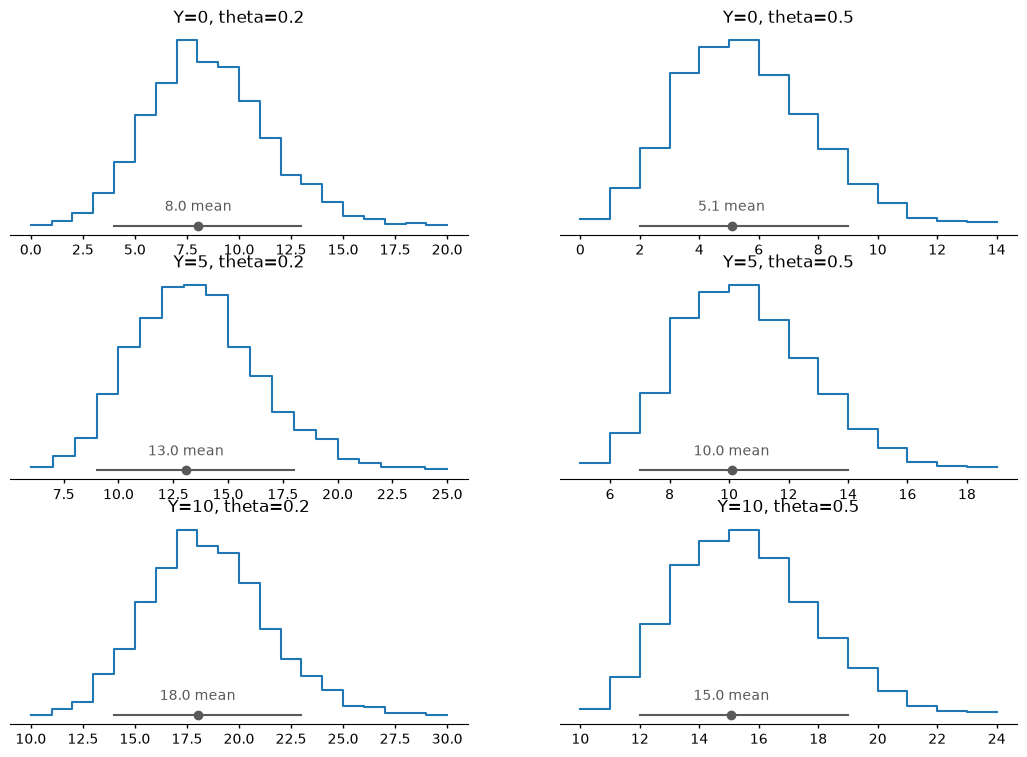

In [5]:
idata_all = az.from_dict({"posterior": posteriori})

# grila 2 x 3, cate un panou pentru fiecare combinatie (Y, theta)
pc = PlotCollection.wrap(
    idata_all.posterior,
    cols="__variable__",
    col_wrap=2,
    backend="matplotlib",
    figure_kwargs={"figsize": (13, 9)},
)
az.plot_dist(idata_all, kind="hist", plot_collection=pc)
pc.show()

In [3]:
print(f"{'Y':>3} {'theta':>6} {'media n':>9} {'HDI 94%':>14}")
for Y in Y_values:
    for theta in theta_values:
        s = posteriori[f"Y={Y}, theta={theta}"].ravel()
        lo, hi = az.hdi(s, prob=0.94)
        print(f"{Y:>3} {theta:>6} {s.mean():>9.2f}   [{lo:.0f}, {hi:.0f}]")

  Y  theta   media n        HDI 94%
  0    0.2      8.04   [3, 13]
  0    0.5      5.08   [1, 9]
  5    0.2     13.08   [8, 18]
  5    0.5     10.08   [6, 14]
 10    0.2     18.01   [13, 23]
 10    0.5     15.08   [11, 19]


## 2) Efectul lui $Y$ și $\theta$ asupra posteriorului

Deoarece $Y \sim \text{Binomial}(n, \theta)$, trebuie ca $n \ge Y$: nu pot cumpăra mai mulți clienți decât au intrat. Pentru $Y = 0$ nu există această limită inferioară, iar priorul $\text{Poisson}(10)$ domină.

### Efectul lui $Y$ (cu $\theta$ fix)

Pe măsură ce $Y$ crește, posteriorul lui $n$ se deplasează spre dreapta: mai mulți cumpărători observați implică mai mulți clienți totali. Aproximativ, media a posteriori urmează regula $n \approx Y/\theta$ influențată de prior, pentru $Y = 5, \theta = 0.5$ obținem $\approx 10$, pentru $Y = 10, \theta = 0.5$ obținem $\approx 15$.

### Efectul lui $\theta$ (cu $Y$ fix).

Pentru același $Y > 0$, un $\theta$ mai mic împinge posteriorul spre valori mai mari ale lui $n$: dacă fiecare client cumpără rar ($\theta = 0.2$), e nevoie de mai mulți clienți ca să explici aceiași $Y$ cumpărători. De aceea, la $Y = 10$, trecerea de la $\theta = 0.5$ ($n \approx 15$) la $\theta = 0.2$ ($n \approx 18$) crește estimarea.

### Cazul $Y = 0$.

Aici datele spun doar că niciun client nu a cumpărat. Cu $\theta$ mai mare, $Y = 0$ devine o dovadă mai puternică de trafic scăzut. Deci posteriorul pentru $\theta = 0.5$ este deplasat mai jos ($\approx 5$) decât pentru $\theta = 0.2$ ($\approx 8$).